# Background shortcut generation

Importing the required libraries

In [54]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

Loading the YAML configuration file

In [55]:
with open("../configs/experiment.yaml", "r") as file:
    config = yaml.safe_load(file)

Loading the Fashion-MNIST training dataset

In [58]:
DATA_DIR = f"../{config['dataset_param']['data_dir']}"
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
if os.path.exists(DATA_DIR):
    try:
        print(f"Dataset found: Loading the dataset from {DATA_DIR}")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False)
    except RuntimeError as e:
        print("Error Dataset not found, downloading the dataset")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)

Dataset found: Loading the dataset from ../data


### Controlled colour-label relationship

Assigning a distinct synthetic colour to each of the ten clothing classes.


| Clothing class | Assigned training cue |
|---|---|
| T-shirt/top | Red |
| Trouser | Blue |
| Pullover | Green |
| Dress | Yellow |
| Coat | Purple |
| Sandal | Orange |
| Shirt | Cyan |
| Sneaker | Pink |
| Bag | Teal |
| Ankle boot | Brown |

### Approach: Colour only zero-valued pixels

In [60]:
CLASS_NAMES = dataset.classes
CLASS_COLORS = np.array(
    config["shortcut_generation_param"]["class_colors"],
    dtype=np.uint8,
)
NEAR_ZERO_INTENSITY_THRESHOLD = config["shortcut_generation_param"]["near_zero_intensity_threshold"]

In [61]:
grayscale_image, label = dataset[0]
grayscale_image = np.array(grayscale_image)
rgb_image = np.stack([grayscale_image] * 3, axis=-1)

near_zero_intensity_mask = grayscale_image < NEAR_ZERO_INTENSITY_THRESHOLD
rgb_image[near_zero_intensity_mask] = CLASS_COLORS[label]

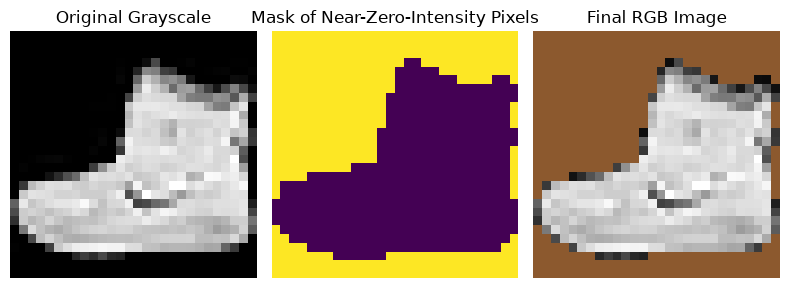

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4))

# Display the original grayscale image
axes[0].imshow(grayscale_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

# Display the mask image
axes[1].imshow(near_zero_intensity_mask)
axes[1].set_title("Mask of Near-Zero-Intensity Pixels")
axes[1].axis("off")

# Display the final RGB image
axes[2].imshow(rgb_image)
axes[2].set_title("Final RGB Image")
axes[2].axis("off")

# Render the plot on screen
plt.tight_layout()
plt.show()